# 12 · Video I/O and background subtraction

**Level:** Intermediate  
**Prerequisites:** Notebooks 01–11; masks, morphology, and contour measurements.

## What you will build and learn

- Generate and save a video without a camera.
- Read frames safely and release device/file resources.
- Build a simple moving-object detector with MOG2.
- Distinguish video frame rate from processing throughput.

## How to use this lesson

Run cells in order with **Shift+Enter**. Predict the result before running each example, then change one parameter and explain what changed. Every default example works offline after setup. Each notebook creates its own data, so previous notebooks do not need to have been run.

Try the exercises before reading the worked solutions. Use **Kernel → Restart Kernel and Run All Cells** to check that your work is reproducible. Keep your own changes in a duplicate notebook if you want to retain the reference version.


## Setup

The cell below imports the libraries and the small display/file helpers. Algorithms are written in the lesson cells. Color arrays passed to `show_images` are assumed to be BGR (OpenCV's usual order); the helper converts them to RGB for Matplotlib. Grayscale arrays are displayed directly. `rng` is a repeatable random generator, so running the notebook again reproduces its sample data.


In [1]:
from pathlib import Path
import sys

# Locate the project whether Jupyter starts in the project or notebooks folder.
start = Path.cwd().resolve()
ROOT = next((p for p in (start, *start.parents) if (p / "course_utils.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from inside the OpenCV Practical project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from course_utils import show_images, make_scene, load_image, save_image

rng = np.random.default_rng(42)
cv2.setRNGSeed(42)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})
print(f"OpenCV {cv2.__version__} | NumPy {np.__version__}")


OpenCV 4.14.0 | NumPy 2.5.3


## Step 1 — Generate a short reproducible video
Video is a time-ordered sequence of images. Every frame written to one video must have the same dimensions and channel layout. We synthesize a moving rectangle over a static background, including initial empty frames to learn the background. No camera or download is needed.


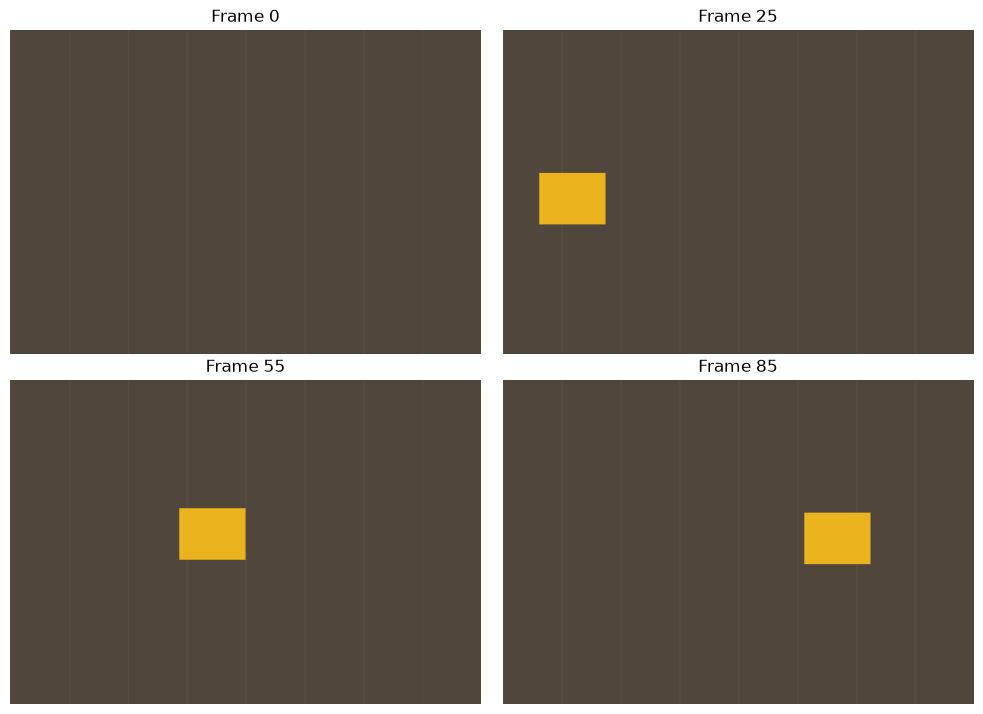

In [2]:
width, height, fps, frame_count = 320, 220, 20.0, 90
background = np.full((height, width, 3), (60, 70, 80), np.uint8)
for x in range(0, width, 40):
    cv2.line(background, (x, 0), (x, height - 1), (67, 77, 87), 1)
frames, truth_masks = [], []
for index in range(frame_count):
    frame = background.copy()
    truth = np.zeros((height, width), np.uint8)
    if index >= 20:
        x = 10 + (index - 20) * 3
        y = 90 + int(20 * np.sin(index / 9))
        cv2.rectangle(frame, (x, y), (x + 44, y + 34), (30, 180, 235), -1)
        cv2.rectangle(truth, (x, y), (x + 44, y + 34), 255, -1)
    frames.append(frame)
    truth_masks.append(truth)
show_images([frames[i] for i in [0, 25, 55, 85]], [f'Frame {i}' for i in [0, 25, 55, 85]], cols=2)
assert all(f.shape == (height, width, 3) and f.dtype == np.uint8 for f in frames)


In [3]:
print('Nominal duration:', frame_count / fps, 'seconds')
print('Raw frame storage:', round(sum(f.nbytes for f in frames) / 1024**2, 2), 'MiB')
print('Frame 40 nominal time:', 40 / fps, 'seconds')


Nominal duration: 4.5 seconds
Raw frame storage: 18.13 MiB
Frame 40 nominal time: 2.0 seconds


## Step 2 — Write video with codec fallbacks and guaranteed release
`VideoWriter` takes a filename, FourCC codec, frames per second, and `(width, height)`. Codec support depends on your OpenCV build. Try MJPG/AVI first and mp4v/MP4 second. Always inspect `isOpened()` and release the writer in `finally`, even after an exception. Video compression is usually lossy, so decoded pixels may differ.


In [4]:
out_dir = ROOT / 'outputs' / '12_video'
out_dir.mkdir(parents=True, exist_ok=True)
video_path = None
writer = None
attempts = [('MJPG', '.avi'), ('mp4v', '.mp4')]
for codec, suffix in attempts:
    candidate_path = out_dir / f'synthetic_motion{suffix}'
    candidate_writer = cv2.VideoWriter(str(candidate_path), cv2.VideoWriter_fourcc(*codec),
                                        fps, (width, height))
    if candidate_writer.isOpened():
        writer, video_path = candidate_writer, candidate_path
        print('Using codec:', codec)
        break
    candidate_writer.release()

if writer is None:
    raise RuntimeError('No tested video codec is available. Check your OpenCV wheel/backend installation.')
try:
    for frame in frames:
        writer.write(frame)
finally:
    writer.release()
assert video_path.exists() and video_path.stat().st_size > 0
print('Saved:', video_path, '| bytes:', video_path.stat().st_size)


Using codec: MJPG
Saved: C:\Users\Hareram ray\AI\OpencvPractical\outputs\12_video\synthetic_motion.avi | bytes: 151136


In [5]:
print('Video I/O backends reported by this OpenCV build:')
build_lines = cv2.getBuildInformation().splitlines()
start = next((i for i, line in enumerate(build_lines) if 'Video I/O:' in line), None)
if start is not None:
    for line in build_lines[start:start + 10]:
        print(line)


Video I/O backends reported by this OpenCV build:
  Video I/O:
    FFMPEG:                      YES (prebuilt binaries)
      avcodec:                   YES (61.19.100)
      avformat:                  YES (61.7.100)
      avutil:                    YES (59.39.100)
      swscale:                   YES (8.3.100)
      avdevice:                  NO
    GStreamer:                   NO
    DirectShow:                  YES
    Orbbec:                      NO


## Step 3 — Read until the stream ends
Check the Boolean `ret` before using a frame. A failed read may mean end of file, unavailable camera, or decoder failure. Metadata such as frame count can be approximate; the actual decoded count is useful evidence. Keep the read loop finite and release the capture in `finally`.


In [6]:
capture = cv2.VideoCapture(str(video_path))
decoded = []
try:
    if not capture.isOpened():
        raise RuntimeError(f'Cannot open saved video: {video_path}')
    reported_fps = capture.get(cv2.CAP_PROP_FPS)
    reported_count = capture.get(cv2.CAP_PROP_FRAME_COUNT)
    print('Reported fps:', reported_fps, '| reported frames:', reported_count)
    for _ in range(frame_count + 5):
        ret, frame = capture.read()
        if not ret:
            break
        decoded.append(frame)
finally:
    capture.release()
print('Actually decoded:', len(decoded))
assert len(decoded) == frame_count
assert decoded[0].shape == frames[0].shape


Reported fps: 20.0 | reported frames: 90.0
Actually decoded: 90


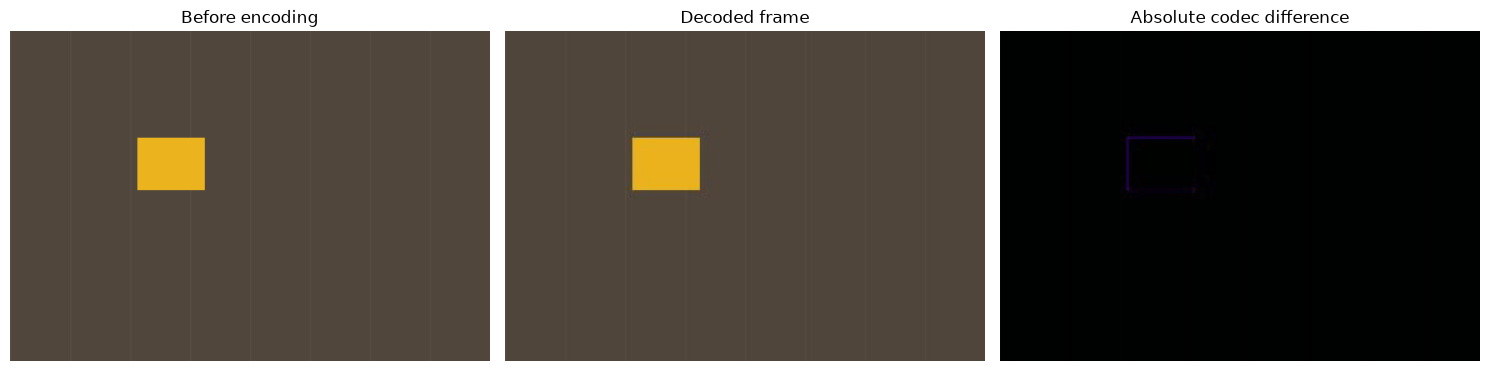

Encoding/decoding MAE: 0.865094696969697


In [7]:
sample_index = 45
codec_difference = cv2.absdiff(frames[sample_index], decoded[sample_index])
show_images([frames[sample_index], decoded[sample_index], codec_difference],
            ['Before encoding', 'Decoded frame', 'Absolute codec difference'])
print('Encoding/decoding MAE:', float(codec_difference.mean()))


Seeking is convenient but can depend on keyframes and decoder behavior. For exact sequential processing, read frames in order. Here, compare a seeked frame with our already decoded list and report any difference.


In [8]:
seek_capture = cv2.VideoCapture(str(video_path))
try:
    if not seek_capture.isOpened():
        raise RuntimeError('Could not reopen the generated video.')
    seek_ok = seek_capture.set(cv2.CAP_PROP_POS_FRAMES, sample_index)
    read_ok, seek_frame = seek_capture.read()
    if seek_ok and read_ok:
        print('Seek-vs-sequential MAE:', float(cv2.absdiff(seek_frame, decoded[sample_index]).mean()))
    else:
        print('This backend did not support the requested seek.')
finally:
    seek_capture.release()


Seek-vs-sequential MAE: 0.0


## Step 4 — Learn a background model with MOG2
MOG2 models each pixel's background over time. `history` controls its adaptation horizon; `varThreshold` controls how easily a pixel matches a background component. `learningRate=0` freezes the model. We explicitly learn the first 20 empty frames, then freeze it so a stationary foreground object will remain foreground in this exercise.


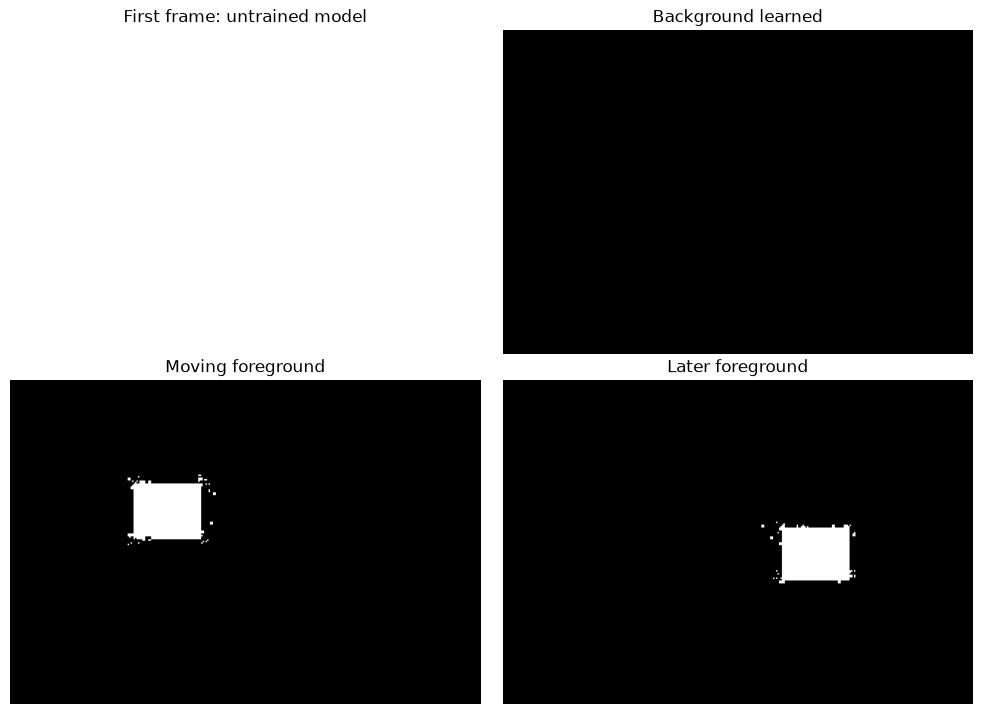

Mask values without shadow detection: [  0 255]


In [9]:
subtractor = cv2.createBackgroundSubtractorMOG2(history=80, varThreshold=25, detectShadows=False)
foreground_masks = []
for index, frame in enumerate(decoded):
    learning_rate = .15 if index < 20 else 0.0
    foreground_masks.append(subtractor.apply(frame, learningRate=learning_rate))
show_images([foreground_masks[i] for i in [0, 19, 45, 80]],
            ['First frame: untrained model', 'Background learned', 'Moving foreground', 'Later foreground'], cols=2)
print('Mask values without shadow detection:', np.unique(foreground_masks[45]))


Shadow-enabled values: [  0 127 255]
Default shadow label: 127


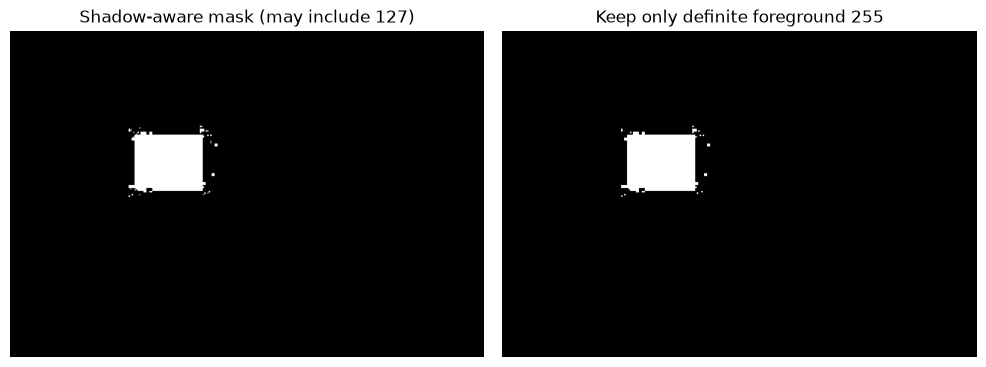

In [10]:
shadow_model = cv2.createBackgroundSubtractorMOG2(history=80, varThreshold=25, detectShadows=True)
for index, frame in enumerate(decoded[:46]):
    shadow_mask = shadow_model.apply(frame, learningRate=.15 if index < 20 else 0)
strict_foreground = np.uint8(shadow_mask == 255) * 255
print('Shadow-enabled values:', np.unique(shadow_mask))
print('Default shadow label:', shadow_model.getShadowValue())
show_images([shadow_mask, strict_foreground], ['Shadow-aware mask (may include 127)', 'Keep only definite foreground 255'], cols=2)


Shadows may receive 127 rather than 255 when enabled. `mask > 0` would include them. For this lesson, treat only 255 as foreground. Real cameras also introduce flicker, autofocus changes, camera motion, and illumination changes that this static synthetic setup avoids.


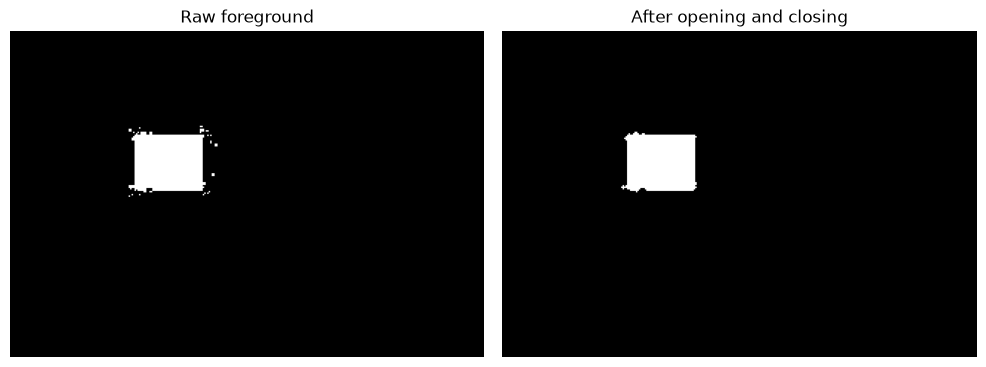

In [11]:
cleanup_kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
clean_masks = []
for mask in foreground_masks:
    binary = np.uint8(mask == 255) * 255
    binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, cleanup_kernel)
    binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, cleanup_kernel)
    clean_masks.append(binary)
show_images([foreground_masks[45], clean_masks[45]], ['Raw foreground', 'After opening and closing'], cols=2)


## Step 5 — Mini-project: annotate moving-object boxes and evaluate masks
Extract contours above a minimum pixel area and draw boxes. This is frame-by-frame detection, not multi-object tracking: we do not assign persistent identities. Evaluate masks after the warmup frames against the generated ground truth.


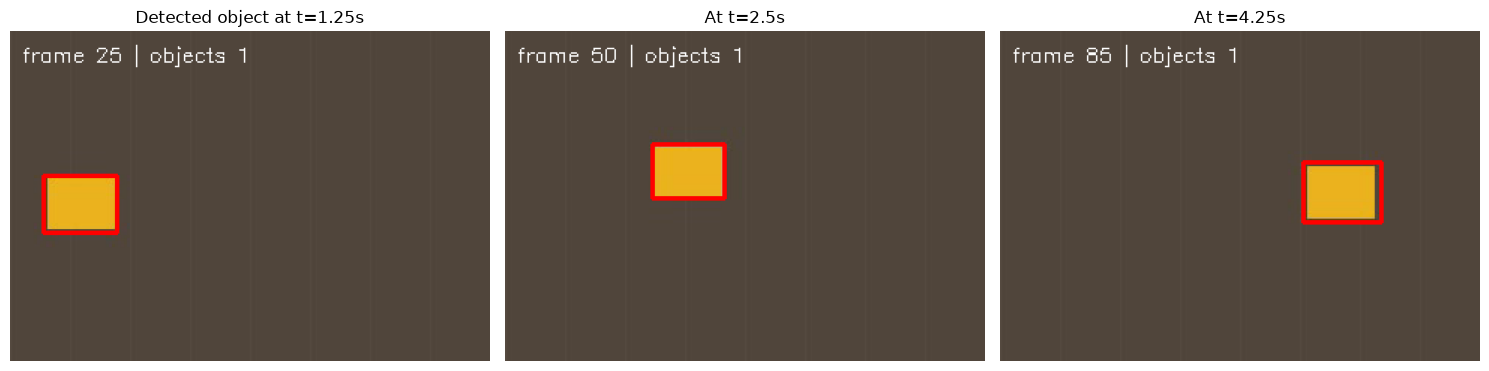

Mean foreground IoU after warmup: 0.9135884914335598


In [12]:
annotated = []
detection_counts, ious = [], []
for index, (frame, mask, truth) in enumerate(zip(decoded, clean_masks, truth_masks)):
    cs, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    objects = [c for c in cs if cv2.contourArea(c) >= 200] if index >= 20 else []
    view = frame.copy()
    for contour in objects:
        x, y, bw, bh = cv2.boundingRect(contour)
        cv2.rectangle(view, (x, y), (x + bw - 1, y + bh - 1), (0, 0, 255), 2)
    cv2.putText(view, f'frame {index:02} | objects {len(objects)}', (8, 20),
                cv2.FONT_HERSHEY_SIMPLEX, .45, (255, 255, 255), 1)
    annotated.append(view)
    detection_counts.append(len(objects))
    if index >= 20:
        p, t = mask > 0, truth > 0
        ious.append(np.count_nonzero(p & t) / max(1, np.count_nonzero(p | t)))
show_images([annotated[i] for i in [25, 50, 85]], ['Detected object at t=1.25s', 'At t=2.5s', 'At t=4.25s'])
print('Mean foreground IoU after warmup:', float(np.mean(ious)))
assert np.mean(ious) > .8, 'The static synthetic background should permit accurate detection.'


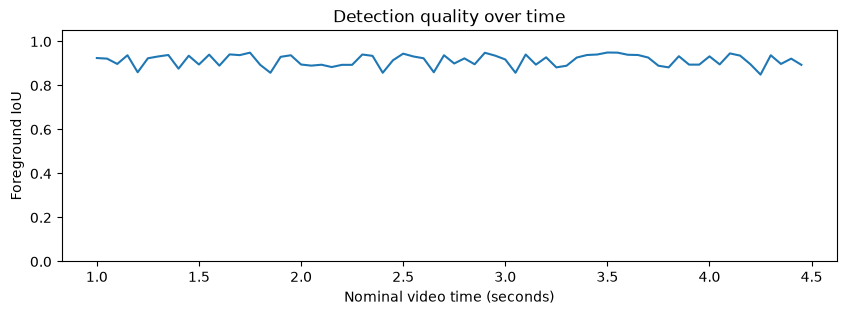

WindowsPath('C:/Users/Hareram ray/AI/OpencvPractical/outputs/12_video/motion_detection_sample.png')

In [13]:
plt.figure(figsize=(10, 3))
plt.plot(np.arange(20, frame_count) / fps, ious)
plt.ylim(0, 1.05); plt.xlabel('Nominal video time (seconds)'); plt.ylabel('Foreground IoU')
plt.title('Detection quality over time'); plt.show()
save_image(out_dir / 'motion_detection_sample.png', annotated[50])


### Timing experiment: source frame rate versus processing throughput
The saved video's 20 FPS specifies playback timing. Processing FPS depends on hardware, image size, and algorithm. Measure only the operation you intend to compare; this example excludes file I/O and rendering. A single tiny benchmark is illustrative, not a hardware performance claim.


In [14]:
from time import perf_counter
benchmark_model = cv2.createBackgroundSubtractorMOG2(history=80, varThreshold=25, detectShadows=False)
start_time = perf_counter()
for frame in decoded:
    benchmark_model.apply(frame)
elapsed = perf_counter() - start_time
print(f'Processing: {len(decoded) / max(elapsed, 1e-9):.1f} FPS over {elapsed:.3f}s')
print(f'Playback: {fps:.1f} FPS, duration {len(decoded) / fps:.2f}s')


Processing: 550.5 FPS over 0.163s
Playback: 20.0 FPS, duration 4.50s


### Optional webcam experiment — OFF by default
Only change `ENABLE_WEBCAM` to `True` when you explicitly want to access your camera. The block captures at most 30 frames and releases the camera even if reading fails. It displays one frame inline and never opens a GUI window. Some backends can block while opening unavailable hardware; leave this disabled for normal Run All.


In [15]:
ENABLE_WEBCAM = False
if ENABLE_WEBCAM:
    webcam = cv2.VideoCapture(0)
    latest_frame = None
    try:
        if not webcam.isOpened():
            raise RuntimeError('Camera unavailable. Check permissions or device index.')
        for _ in range(30):
            ok, frame = webcam.read()
            if not ok:
                break
            latest_frame = frame
    finally:
        webcam.release()
    if latest_frame is not None:
        show_images([latest_frame], ['Optional camera sample'])
else:
    print('Webcam disabled. All core lessons use the generated video.')


Webcam disabled. All core lessons use the generated video.


### Practice
1. Compute the mean detected-object count after warmup and the fraction of frames with exactly one detection.
2. Let MOG2 adapt while an object remains stationary for many frames. Compare it with a frozen model.
3. Write an annotated result video using the selected codec/container. Check opening and release it reliably.

## Worked solutions
For the adaptation experiment, repeat the same object frame. This isolates learning behavior from motion and compression changes.


Mean detections: 1.0
Exactly one detection: 1.0


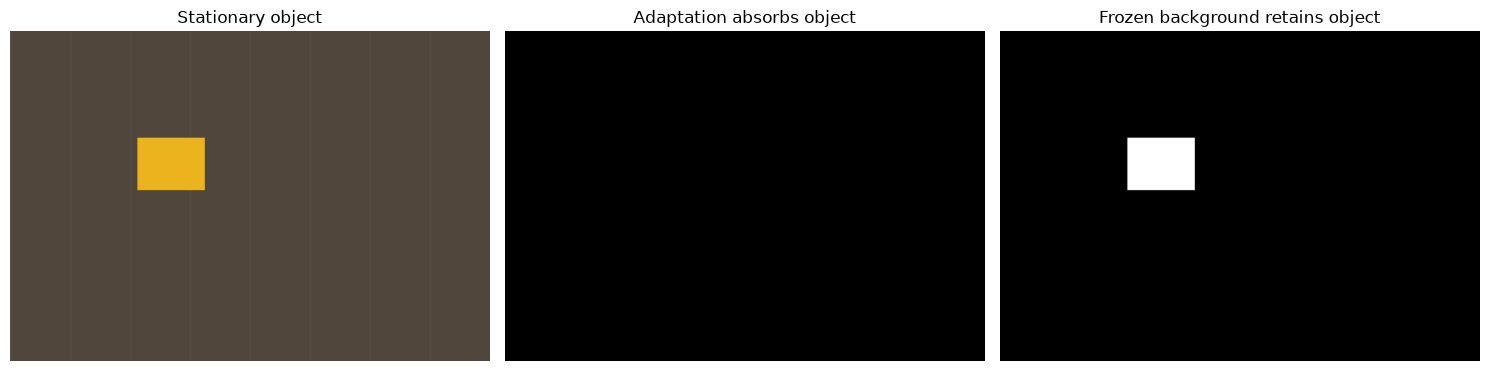

In [16]:
counts = np.asarray(detection_counts[20:])
print('Mean detections:', counts.mean())
print('Exactly one detection:', np.mean(counts == 1))
adapt_model = cv2.createBackgroundSubtractorMOG2(history=80, varThreshold=25, detectShadows=False)
freeze_model = cv2.createBackgroundSubtractorMOG2(history=80, varThreshold=25, detectShadows=False)
for _ in range(25):
    adapt_model.apply(background, learningRate=.2)
    freeze_model.apply(background, learningRate=.2)
stationary = frames[45]
for _ in range(100):
    adaptive_mask = adapt_model.apply(stationary, learningRate=.05)
    frozen_mask = freeze_model.apply(stationary, learningRate=0)
show_images([stationary, adaptive_mask, frozen_mask], ['Stationary object', 'Adaptation absorbs object', 'Frozen background retains object'])
assert np.count_nonzero(adaptive_mask) < np.count_nonzero(frozen_mask)


In [17]:
annotated_path = out_dir / f'annotated_motion{video_path.suffix}'
selected_codec = 'MJPG' if video_path.suffix == '.avi' else 'mp4v'
output_writer = cv2.VideoWriter(str(annotated_path), cv2.VideoWriter_fourcc(*selected_codec),
                                fps, (width, height))
try:
    if not output_writer.isOpened():
        raise RuntimeError('Unable to open annotated output writer.')
    for frame in annotated:
        output_writer.write(frame)
finally:
    output_writer.release()
print('Annotated video:', annotated_path)
assert annotated_path.exists() and annotated_path.stat().st_size > 0


Annotated video: C:\Users\Hareram ray\AI\OpencvPractical\outputs\12_video\annotated_motion.avi


### Reflection
Why does the first foreground mask often mark nearly the whole frame? What happens when the camera moves? When would you freeze a background model, and when would adaptation be essential?

Official references: [Video capture tutorial](https://docs.opencv.org/4.x/dd/d43/tutorial_py_video_display.html), [Background subtraction](https://docs.opencv.org/4.x/d1/dc5/tutorial_background_subtraction.html), [VideoWriter API](https://docs.opencv.org/4.x/dd/d9e/classcv_1_1VideoWriter.html), [MOG2 API](https://docs.opencv.org/4.x/d7/d7b/classcv_1_1BackgroundSubtractorMOG2.html).
